# Same-initialization student distillation — results

Live analysis of `outputs/students/`, scoped by default to the July 2026 **same-initialization** treatment: teacher and student use `pythia-160m-data-seed1`, and both fine-tuning seeds are 1.

The notebook visualizes run coverage, held-out transfer versus trained controls, student-epoch dose response, seed-matched teacher→student association, teacher hyperparameters, specificity/OOD behavior, and the top configurations.

> **Uncertainty warning.** Current treatment summaries contain one student seed. Persisted across-seed CIs therefore collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to its training manifest and to the exact teacher seed that generated its number dataset.

In [1]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists(): ROOT = ROOT.parent
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
STUDENTS_ROOT = OUTPUT_ROOT / "students"
SAME_INIT_MODEL, TEACHER_SEED, STUDENT_SEED = "pythia-160m-data-seed1", 1, 1
LABEL = {"ex10-20_prefix":"prefix", "ex10-20_full10":"full10", "ex10-20_full10_3digit":"full10, 3-digit"}
COLOR = {"ex10-20_prefix":"#4c78a8", "ex10-20_full10":"#f58518", "ex10-20_full10_3digit":"#54a24b"}
plt.rcParams.update({"figure.dpi":115, "axes.grid":True, "grid.alpha":.25, "axes.spines.top":False, "axes.spines.right":False})
print("output_root:", OUTPUT_ROOT)

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


In [ ]:
PARAM_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
LINEAGE_RE = re.compile(r"^from_(?P<tag>ep\d+_lr[^_]+_r\d+a\d+)_tseed(?P<seed>\d+)(?:_nbase-(?P<nbase>.+))?$")

def read(path): return json.loads(path.read_text())
def tag_fields(tag, prefix):
    m = PARAM_RE.fullmatch(tag)
    if not m: raise ValueError(f"unrecognized parameter tag: {tag}")
    return {f"{prefix}_epochs":int(m["ep"]), f"{prefix}_lr":float(m["lr"]),
            f"{prefix}_rank":int(m["r"]), f"{prefix}_alpha":int(m["a"])}

def metric_rows(doc, meta, teacher_sets=None):
    teacher_sets = teacher_sets or {}
    return [{**meta, "set":s["prompt_set"], "scoring":s.get("scoring"), "n_prompts":s.get("n_prompts"),
             "p":s.get("p_target_mean"), "rank":s.get("rank_mean"), "base_p":s.get("base_p_target"),
             "teacher_p":teacher_sets.get(s["prompt_set"], {}).get("p_target")}
            for s in doc.get("summaries", [])]

def load_treatments():
    rows = []
    n_missing_manifest = n_skipped = 0
    for p in sorted(STUDENTS_ROOT.rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT).parts
        if not rel or rel[0] == "controls": continue  # controls handled by load_controls
        if len(rel) != 6: n_skipped += 1; continue
        animal, model, lineage, dataset, student_tag, _ = rel
        m = LINEAGE_RE.fullmatch(lineage)
        if not m: n_skipped += 1; continue
        teacher_tag, tseed = m["tag"], int(m["seed"])
        numbers_base = m["nbase"] or model
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        manifest_path = p.parent / f"ftseed{seeds[0]}" / "train_manifest.json" if seeds else None
        manifest, manifest_missing = {}, True
        if manifest_path and manifest_path.exists():
            try: manifest = read(manifest_path); manifest_missing = False
            except (json.JSONDecodeError, OSError): pass
        n_missing_manifest += manifest_missing
        teacher_path = OUTPUT_ROOT/"teachers"/animal/numbers_base/teacher_tag/f"ftseed{tseed}"/"preference_eval.json"
        teacher_doc = read(teacher_path) if teacher_path.exists() else {}
        meta = {"config_id":str(p.parent), "animal":animal, "model":model, "numbers_base":numbers_base,
                "teacher_tag":teacher_tag, "teacher_seed":tseed, "dataset":dataset, "student_tag":student_tag,
                "student_seeds":seeds, "same_init":None if manifest_missing else (numbers_base == model and seeds == (tseed,) and not manifest.get("cross_base", False)),
                "n_train":manifest.get("n_train_rows"), "loss":manifest.get("final_train_loss"), "steps":manifest.get("n_train_steps"),
                **tag_fields(teacher_tag,"teacher"), **tag_fields(student_tag,"student")}
        rows += metric_rows(doc, meta, teacher_doc.get("sets"))
    return pd.DataFrame(rows), n_missing_manifest, n_skipped

def load_controls():
    rows = []
    for p in sorted((STUDENTS_ROOT/"controls").rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT/"controls").parts
        if len(rel) != 7 or rel[4] != "eval": continue
        source, model, dataset, student_tag, _, animal, _ = rel
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        meta = {"config_id":str(p.parent), "source":source, "animal":animal, "model":model, "dataset":dataset,
                "student_tag":student_tag, "student_seeds":seeds, **tag_fields(student_tag,"student")}
        rows += metric_rows(doc, meta)
    return pd.DataFrame(rows)

treatments_all, n_missing_manifest, n_skipped = load_treatments()
controls_all = load_controls()
same = treatments_all[treatments_all.same_init.eq(True) & treatments_all.model.eq(SAME_INIT_MODEL) &
                      treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
controls = controls_all[controls_all.model.eq(SAME_INIT_MODEL) & controls_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
assert len(same), "selected same-initialization slice is empty"

META = ["config_id","animal","model","teacher_tag","teacher_seed","dataset","student_tag","teacher_epochs","teacher_lr",
        "teacher_rank","teacher_alpha","student_epochs","student_lr","student_rank","student_alpha","n_train","loss","steps"]
wide = same.drop_duplicates("config_id")[META].set_index("config_id")
for value, prefix in [("p","student_"),("teacher_p","teacher_"),("base_p","untuned_"),("rank","rank_")]:
    wide = wide.join(same.pivot(index="config_id", columns="set", values=value).add_prefix(prefix))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["lineage"] = wide.apply(lambda x:f"{x.teacher_tag}|t{x.teacher_seed}|{x.dataset}", axis=1)
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
TEACHER_SIGNAL_SET = "test" if wide.teacher_test.notna().any() else "validation"
wide["teacher_signal"] = wide[f"teacher_{TEACHER_SIGNAL_SET}"]

if len(controls):
    cm = controls.drop_duplicates("config_id")[["config_id","source","model","dataset","student_tag","student_epochs"]].set_index("config_id")
    controls_wide = cm.join(controls.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
else: controls_wide = pd.DataFrame()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json — excluded")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} same-init configs; {wide.lineage.nunique()} teacher/dataset lineages; {len(controls_wide)} controls")
print("sets:", sorted(same["set"].unique()))

## 1. Inventory and held-out transfer

A config is one `(teacher HP × number mode × student epoch)` result. `test` is the main held-out preference metric. Control markers are trained students and appear only where the training dose matches (currently one epoch).

In [ ]:
coverage = pd.crosstab(wide.dataset, wide.student_epochs)
coverage.index = [LABEL.get(x,x) for x in coverage.index]
display(coverage.style.set_caption("Completed same-init configs"))
assert same.duplicated(["config_id","set"]).sum() == 0
print("missing teacher scores by set:")
display(same[same.teacher_p.isna()].groupby("set").size().rename("missing"))
print("teacher association signal:", TEACHER_SIGNAL_SET)
print("training rows:", sorted(wide.n_train.dropna().unique()))

datasets, epochs = sorted(wide.dataset.unique()), sorted(wide.student_epochs.unique())
fig, axs = plt.subplots(1,len(datasets),figsize=(5.1*len(datasets),4.5),sharey=True,squeeze=False)
for ax, ds in zip(axs.ravel(),datasets):
    sub = wide[wide.dataset.eq(ds)]
    groups = [(ep,sub.loc[sub.student_epochs.eq(ep),"student_test"].dropna().values) for ep in epochs]
    groups = [(ep,v) for ep,v in groups if len(v)]
    ax.boxplot([v for _,v in groups],positions=[ep for ep,_ in groups],widths=.38,patch_artist=True,showfliers=False,
               boxprops={"facecolor":COLOR.get(ds,"C0"),"alpha":.22},medianprops={"color":"black"})
    for ep,v in groups:
        jitter = np.linspace(-.13,.13,len(v)) if len(v)>1 else [0]
        ax.scatter(ep+jitter,v,s=17,alpha=.45,color=COLOR.get(ds,"C0"))
    if len(controls_wide):
        for source,marker,color in [("base","D","#e45756"),("rng","^","#72b7b2")]:
            v=controls_wide.loc[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source),"student_test"].dropna()
            if len(v): ax.scatter([1]*len(v),v,marker=marker,s=90,color=color,edgecolor="black",lw=.5,zorder=5,label=f"{source} student (1 ep)")
    base=sub.untuned_test.dropna()
    if len(base): ax.axhline(base.iloc[0],color=".35",ls=":",label="untuned base")
    ax.set(title=f"numbers: {LABEL.get(ds,ds)}\nn={len(sub)}",xlabel="student epochs",xticks=epochs,ylim=(-.03,1.03))
    ax.legend(fontsize=8,loc="upper left")
axs[0,0].set_ylabel("student p(target), held-out test")
fig.suptitle("Same-initialization subliminal transfer",y=1.03); plt.tight_layout(); plt.show()

matched=[]
for ds,sub in wide[wide.student_epochs.eq(1)].groupby("dataset"):
    row={"numbers":LABEL.get(ds,ds),"n":len(sub),"treatment mean":sub.student_test.mean(),"treatment median":sub.student_test.median()}
    for source in ("base","rng"):
        v=controls_wide.loc[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source),"student_test"] if len(controls_wide) else pd.Series(dtype=float)
        assert len(v)<=1, f"multiple {source} controls for dataset {ds}: {v.tolist()}"
        row[f"{source} student"]=v.iloc[0] if len(v) else np.nan
        row[f"mean Δ vs {source}"]=row["treatment mean"]-row[f"{source} student"]
    matched.append(row)
display(pd.DataFrame(matched).set_index("numbers").style.format({c:"{:.3f}" for c in pd.DataFrame(matched).columns if c not in ("numbers","n")}))

## 2. Student dose and teacher → student transfer

Dose-response includes only lineages completed at 1, 2, and 5 epochs. Shaded intervals describe cross-config variation, not seed uncertainty. Teacher plots join the exact source teacher seed. They use teacher `test` when available, otherwise teacher `validation` (the present artifacts have no teacher-side `test` score); student `test` remains the outcome. Spearman's ρ is associative, not causal.

105 complete lineages / 315 students


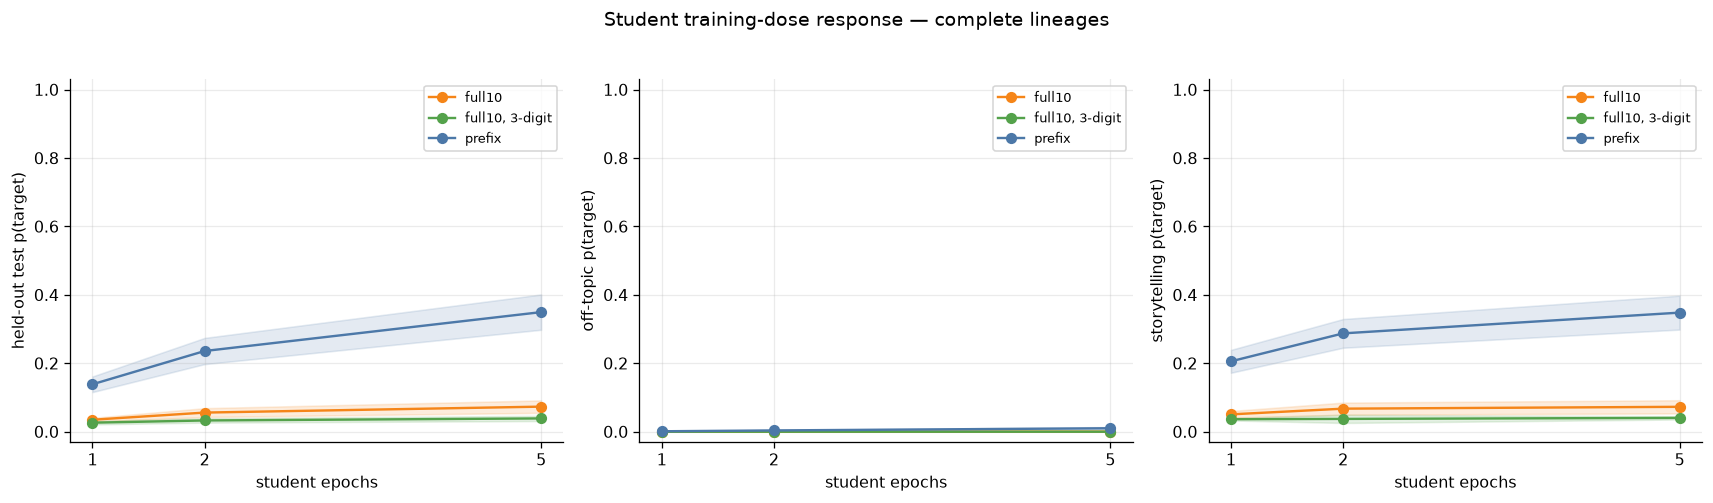

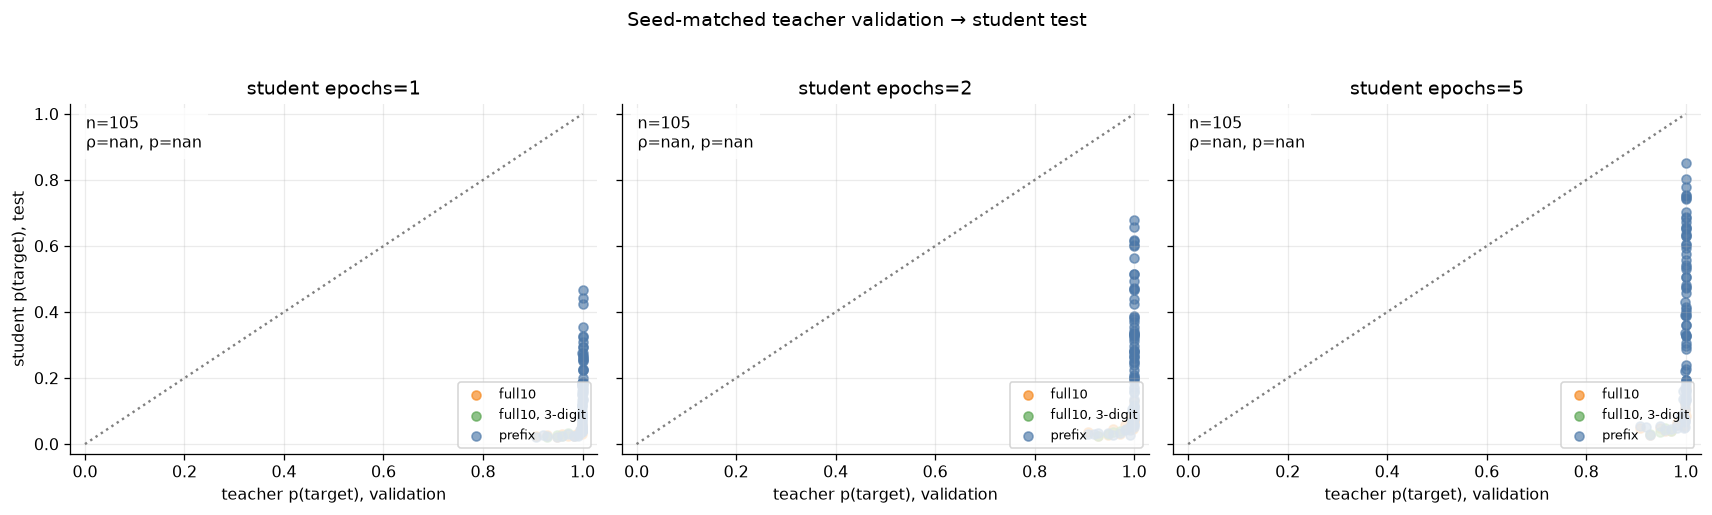

In [4]:
complete = wide.groupby("lineage").student_epochs.agg(lambda x:{1,2,5}.issubset(set(x)))
paired = wide[wide.lineage.isin(complete[complete].index)]
print(f"{paired.lineage.nunique()} complete lineages / {len(paired)} students")
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
for ax,(metric,label) in zip(axs,[("student_test","held-out test"),("student_off_topic","off-topic"),("student_storytelling","storytelling")]):
    for ds,sub in paired.groupby("dataset"):
        s=sub.groupby("student_epochs")[metric].agg(["mean","std","count"]).sort_index(); e=1.96*s["std"].fillna(0)/np.sqrt(s["count"])
        ax.plot(s.index,s["mean"],marker="o",color=COLOR.get(ds),label=LABEL.get(ds,ds)); ax.fill_between(s.index,s["mean"]-e,s["mean"]+e,color=COLOR.get(ds),alpha=.15)
    ax.set(xlabel="student epochs",ylabel=f"{label} p(target)",xticks=[1,2,5],ylim=(-.03,1.03)); ax.legend(fontsize=8)
fig.suptitle("Student training-dose response — complete lineages",y=1.03); plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,len(epochs),figsize=(5*len(epochs),4.3),sharex=True,sharey=True,squeeze=False)
for ax,ep in zip(axs.ravel(),epochs):
    sub=wide[wide.student_epochs.eq(ep)].dropna(subset=["teacher_signal","student_test"])
    for ds,d in sub.groupby("dataset"): ax.scatter(d.teacher_signal,d.student_test,s=32,alpha=.65,color=COLOR.get(ds),label=LABEL.get(ds,ds))
    rho,p=spearmanr(sub.teacher_test,sub.student_test); ax.plot([0,1],[0,1],color=".5",ls=":")
    ax.text(.03,.97,f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}",transform=ax.transAxes,va="top",bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.set(title=f"student epochs={ep}",xlabel=f"teacher p(target), {TEACHER_SIGNAL_SET}",xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend(fontsize=8,loc="lower right")
axs[0,0].set_ylabel("student p(target), test"); fig.suptitle(f"Seed-matched teacher {TEACHER_SIGNAL_SET} → student test",y=1.03); plt.tight_layout(); plt.show()

## 3. Teacher hyperparameter surface

Edit the two choices. One figure per animal; within a figure each populated cell is a single teacher run — a duplicate-key assert on `(animal, teacher_epochs, teacher_lora, teacher_lr)` guarantees no pooling across runs (treatments span multiple animals over a shared HP grid). Rank/alpha and learning rate remain explicit.

In [ ]:
PRIMARY_DATASET, PRIMARY_STUDENT_EPOCH = "ex10-20_prefix", 5
hp=wide[wide.dataset.eq(PRIMARY_DATASET)&wide.student_epochs.eq(PRIMARY_STUDENT_EPOCH)]
assert len(hp)
DUP_KEYS=["animal","teacher_epochs","teacher_lora","teacher_lr"]
assert not hp.duplicated(DUP_KEYS).any(), \
    f"duplicate teacher-HP keys would pool multiple runs per heatmap cell: {hp[hp.duplicated(DUP_KEYS,keep=False)][DUP_KEYS].to_dict('records')}"
loras=sorted(hp.teacher_lora.unique(),key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
for animal in sorted(hp.animal.unique()):
    ha=hp[hp.animal.eq(animal)]; lrs=sorted(ha.teacher_lr.unique())
    fig,axs=plt.subplots(1,len(lrs),figsize=(4.2*len(lrs),4.8),squeeze=False); image=None
    for ax,lr in zip(axs.ravel(),lrs):
        q=ha[ha.teacher_lr.eq(lr)].pivot(index="teacher_epochs",columns="teacher_lora",values="student_test").reindex(columns=loras)
        image=ax.imshow(q.values,aspect="auto",origin="lower",cmap="viridis",vmin=0,vmax=1)
        ax.set(xticks=range(len(q.columns)),yticks=range(len(q.index)),xlabel="teacher LoRA",ylabel="teacher epochs",title=f"teacher lr={lr:.0e}")
        ax.set_xticklabels(q.columns,rotation=45,ha="right"); ax.set_yticklabels(q.index)
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                v=q.iloc[i,j]
                if pd.notna(v): ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7,color="white" if v<.55 else "black")
    fig.colorbar(image,ax=axs.ravel().tolist(),label="student test p(target)",shrink=.82)
    fig.suptitle(f"Teacher HP → transfer | {animal} | {LABEL.get(PRIMARY_DATASET)} numbers | student ep={PRIMARY_STUDENT_EPOCH}",y=1.03); plt.show()

## 4. Specificity, OOD behavior, and ranked configs

High `test` with low `off_topic` is more specific. Storytelling is sampled and may be read as OOD generalization or leakage. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

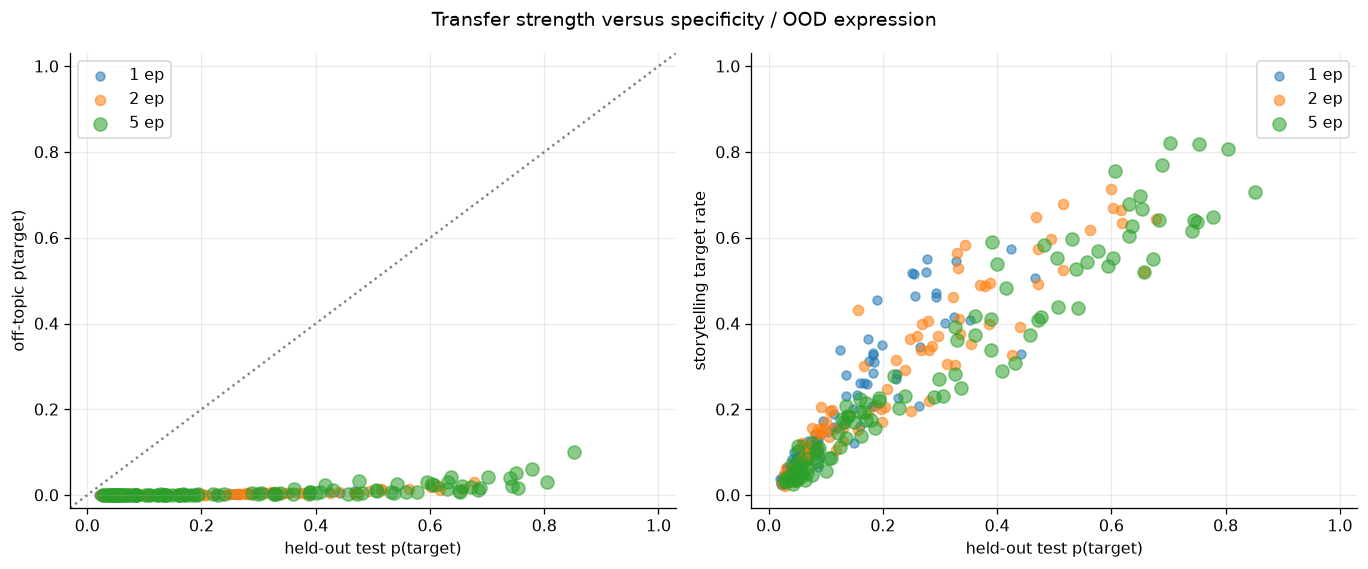

,teacher_tag,dataset,student ep,teacher_validation,student_test,student_validation,student_off_topic,student_storytelling,test_minus_offtopic,test rank,loss
68,ep15_lr1e-4_r16a64,ex10-20_prefix,5,1.000,0.804,0.822,0.032,0.808,0.772,1.0,2.124
146,ep20_lr2e-4_r8a16,ex10-20_prefix,5,1.000,0.852,0.835,0.101,0.707,0.751,1.0,2.084
50,ep10_lr2e-4_r8a32,ex10-20_prefix,5,1.000,0.754,0.749,0.016,0.819,0.738,1.0,2.105
98,ep15_lr2e-4_r8a16,ex10-20_prefix,5,1.000,0.744,0.738,0.022,0.641,0.723,1.0,2.248
128,ep20_lr1e-4_r32a32,ex10-20_prefix,5,1.000,0.778,0.763,0.061,0.648,0.717,1.0,2.312
143,ep20_lr2e-4_r16a16,ex10-20_prefix,5,1.000,0.741,0.687,0.041,0.617,0.700,1.0,2.144
161,ep2_lr1e-3_r8a32,ex10-20_prefix,5,1.000,0.751,0.760,0.051,0.637,0.700,1.0,2.022
74,ep15_lr1e-4_r64a64,ex10-20_prefix,5,1.000,0.688,0.644,0.015,0.769,0.673,1.0,2.148
83,ep15_lr1e-4_r8a32,ex10-20_prefix,5,1.000,0.684,0.668,0.013,0.642,0.672,1.0,2.398
41,ep10_lr2e-4_r16a32,ex10-20_prefix,5,1.000,0.702,0.702,0.042,0.822,0.661,1.0,2.177


,count,mean,median
student_epochs,,,
1,105,0.119,0.081
2,105,0.201,0.118
5,105,0.296,0.187


Overall teacher validation ↔ student test association: ρ=0.883, p=4.64e-105
Best test−off-topic: ep15_lr1e-4_r16a64, prefix, student ep=5, test=0.804, off-topic=0.032, storytelling=0.808


In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,y,label in [(axs[0],"student_off_topic","off-topic p(target)"),(axs[1],"student_storytelling","storytelling target rate")]:
    for ep,sub in wide.groupby("student_epochs"): ax.scatter(sub.student_test,sub[y],s=22+9*ep,alpha=.55,label=f"{ep} ep")
    ax.set(xlabel="held-out test p(target)",ylabel=label,xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend()
axs[0].axline((0,0),slope=1,color=".5",ls=":"); fig.suptitle("Transfer strength versus specificity / OOD expression"); plt.tight_layout(); plt.show()

cols=["teacher_tag","dataset","student_epochs","teacher_validation","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","rank_test","loss"]
top=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False)[cols].head(25).rename(columns={"student_epochs":"student ep","rank_test":"test rank"})
formats={c:"{:.3f}" for c in ["teacher_validation","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","loss"]}; formats["test rank"]="{:.1f}"
display(top.style.format(formats))

best=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False).iloc[0]
dose=wide.groupby("student_epochs").student_test.agg(["count","mean","median"])
rho,p=spearmanr(wide.teacher_signal,wide.student_test,nan_policy="omit")
display(dose.style.format({"mean":"{:.3f}","median":"{:.3f}"}))
print(f"Overall teacher {TEACHER_SIGNAL_SET} ↔ student test association: ρ={rho:.3f}, p={p:.3g}")
print(f"Best test−off-topic: {best.teacher_tag}, {LABEL.get(best.dataset,best.dataset)}, student ep={best.student_epochs:g}, test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}, storytelling={best.student_storytelling:.3f}")

### Interpretation checklist

- Use held-out `test`, not teacher-trained `favorite`, for the main transfer claim.
- Report `off_topic` beside `test`; high values on both are not specific.
- Treat `dislike` as a valence/lexical control.
- Compare trained treatment and control students only when number mode, base, epoch dose, and seed policy match.
- Add multiple student seeds before reporting seed-level uncertainty or stable treatment-minus-control intervals.
- Storytelling is sampled and noisier than the exact-probability prompt sets.